# 09 — From price movement to a conditional probability

**Question:** How do distance, volatility and time affect a simple digital model?

**By the end:** derive a normal-return event probability, read sensitivity curves,
compare a deliberately provisional proxy model with quotes, and distinguish model
disagreement from measured edge. **Time:** 35–45 minutes.

**Inputs:** recorded BTC trades and outcome quotes, plus clearly marked synthetic
model scenarios. This sample does not qualify the actual threshold or settlement
functional. No actual-contract fair value, calibration score or winner is invented.

In [1]:
import sys
from pathlib import Path

for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tyrex_pm.research.tuto_btc5m.advanced import (
    digital_probability,
    feature_dataset,
)
from tyrex_pm.research.tuto_btc5m.analysis import (
    BookStudy,
    btc_grid,
    finish_plot,
    plot_style,
)
from tyrex_pm.research.tuto_btc5m.data import Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. State the mathematical assumption before calculating

Suppose an **illustrative endpoint contract** pays $1 when terminal price is at
least K. Let the remaining log return R be normal with mean m and variance V.
With distance d = log(S/K), Up occurs when d + R is nonnegative, hence

\[
p_{\mathrm{toy}}=\Phi\left(\frac{d+m}{\sqrt V}\right).
\]

We use m = 0 as a teaching assumption. V is the **integrated remaining return
variance**, not a daily volatility number. This is a conditional event probability
under an assumed physical distribution, not a risk-neutral price or verified PM
settlement model. A TWAP-based rule would require a different random variable.
At zero variance, the toy's explicit “at least” tie rule determines the payout.

In [2]:
display(
    pd.DataFrame(
        [
            {
                "log_distance": d,
                "remaining_variance": v,
                "toy_probability": digital_probability(d, v),
            }
            for d, v in [(0, 1e-6), (0.001, 1e-6), (-0.001, 1e-6), (0, 0)]
        ]
    )
)
assert digital_probability(0, 1e-6) == 0.5
print("Actual-contract pricing status:", sample.quality.get("semantic_readiness", "NOT_REPORTED"))

,log_distance,remaining_variance,toy_probability
0,0.000,0.000001,0.500000
1,0.001,0.000001,0.841345
2,-0.001,0.000001,0.158655
3,0.000,0.000000,1.000000


Actual-contract pricing status: UNSUPPORTED


## 2. Volatility changes confidence, not direction

In the centered normal-log-return toy, greater remaining uncertainty draws an
estimate toward 50%. At exactly zero distance and zero mean, all positive
variances give 50%. This symmetry is a property of this model, not a universal
statement about every BTC distribution or contract rule.

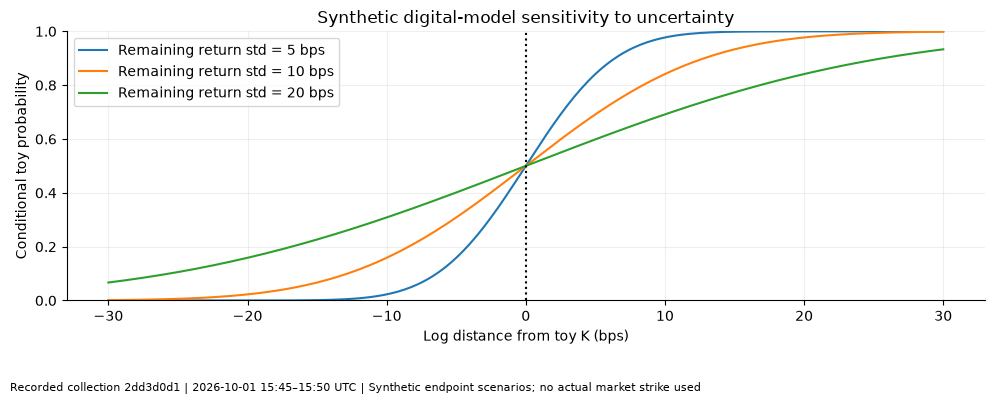

In [3]:
distance_bps = np.linspace(-30, 30, 241)
fig, ax = plt.subplots()
for remaining_std_bps in [5, 10, 20]:
    p = digital_probability(distance_bps / 10000, (remaining_std_bps / 10000) ** 2)
    ax.plot(distance_bps, p, label=f"Remaining return std = {remaining_std_bps} bps")
ax.axvline(0, color="black", linestyle=":")
ax.set(
    title="Synthetic digital-model sensitivity to uncertainty",
    xlabel="Log distance from toy K (bps)",
    ylabel="Conditional toy probability",
    ylim=(0, 1),
)
ax.legend()
finish_plot(fig, sample, "Synthetic endpoint scenarios; no actual market strike used")

## 3. Time remaining amplifies sensitivity near the boundary

Assume a constant return standard deviation of 1 basis point per square-root
second, so V = sigma² × seconds remaining. Shorter time can make a small distance
more decisive. Jumps, uncertain reference prices and estimation error can invalidate
this smooth picture. It is not a reason to quote tightly near expiry.

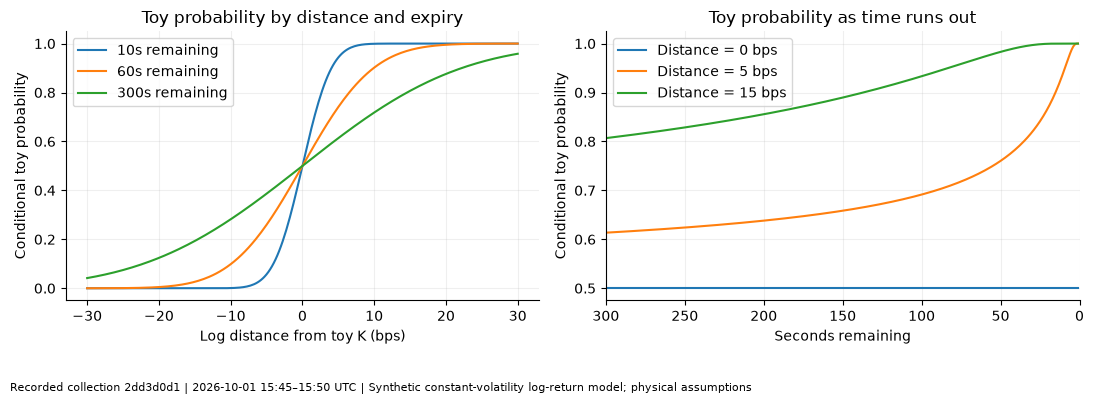

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for tau in [10, 60, 300]:
    p = digital_probability(distance_bps / 10000, (1 / 10000) ** 2 * tau)
    axes[0].plot(distance_bps, p, label=f"{tau}s remaining")
axes[0].set(
    title="Toy probability by distance and expiry",
    xlabel="Log distance from toy K (bps)",
    ylabel="Conditional toy probability",
)
axes[0].legend()
taus = np.arange(1, 301)
for d in [0, 5, 15]:
    axes[1].plot(
        taus, digital_probability(d / 10000, (1 / 10000) ** 2 * taus), label=f"Distance = {d} bps"
    )
axes[1].set(
    title="Toy probability as time runs out",
    xlabel="Seconds remaining",
    ylabel="Conditional toy probability",
    xlim=(300, 0),
)
axes[1].legend()
finish_plot(fig, sample, "Synthetic constant-volatility log-return model; physical assumptions")

## 4. Connect the mathematics to recorded data, without pretending K is known

Our visual proxy K is the first eligible Binance grid price, and is available only
from its actual arrival onward. A trailing twenty-return standard deviation gives
a noisy volatility proxy. Assuming that proxy persists until expiry is another
strong assumption. We compare the resulting **proxy model** with observed Up midpoints.

The plotted gap is model disagreement. It is not an EV estimate, calibration
result, or trading signal. Neither this proxy K nor Binance defines actual settlement.

Proxy K: 83889.44 USDT/BTC, available at 2026-10-01 15:45:01+00:00 ; not the official threshold.


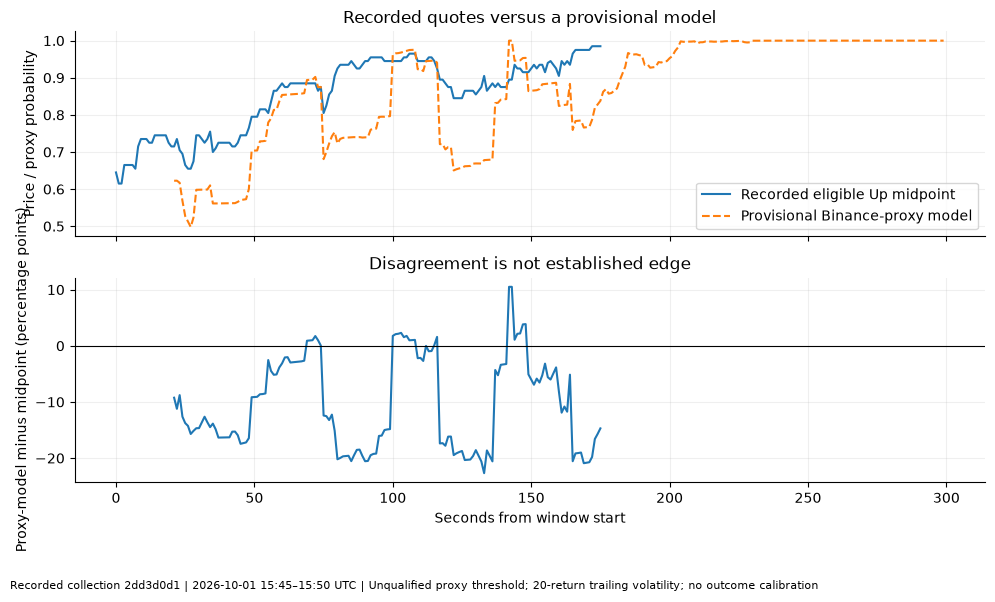

In [5]:
study = BookStudy(sample)
features = feature_dataset(sample, study)
btc = btc_grid(sample)
anchor_row = btc[btc.eligible].iloc[0]
proxy_k, proxy_at = anchor_row.price_float, anchor_row.time
distance = np.log(btc.price_float.to_numpy() / proxy_k)
variance = (features.btc_volatility_bps.to_numpy() / 10000) ** 2 * features.seconds_left.to_numpy()
features["proxy_model_probability"] = digital_probability(distance, variance)
features.loc[features.time < proxy_at, "proxy_model_probability"] = np.nan
features["proxy_model_gap"] = features.proxy_model_probability - features.mid
print("Proxy K:", proxy_k, "USDT/BTC, available at", proxy_at, "; not the official threshold.")
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
x = (features.time - pd.Timestamp(sample.start, tz="UTC")).dt.total_seconds()
axes[0].plot(x, features.mid, label="Recorded eligible Up midpoint")
axes[0].plot(
    x, features.proxy_model_probability, label="Provisional Binance-proxy model", linestyle="--"
)
axes[0].set(title="Recorded quotes versus a provisional model", ylabel="Price / proxy probability")
axes[0].legend()
axes[1].plot(x, features.proxy_model_gap * 100)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(
    title="Disagreement is not established edge",
    xlabel="Seconds from window start",
    ylabel="Proxy-model minus midpoint (percentage points)",
)
finish_plot(
    fig,
    sample,
    "Unqualified proxy threshold; 20-return trailing volatility; no outcome calibration",
)

## 5. Reference uncertainty can erase apparent precision

If uncertainty about the endpoint log-distance is independent and normal with
variance v, the toy denominator becomes sqrt(V + v). Bias b shifts distance to
d − b. Independence, normality, b and v must be justified with data; they are not
automatically the observed instant-trade versus TWAP difference from notebook 08.

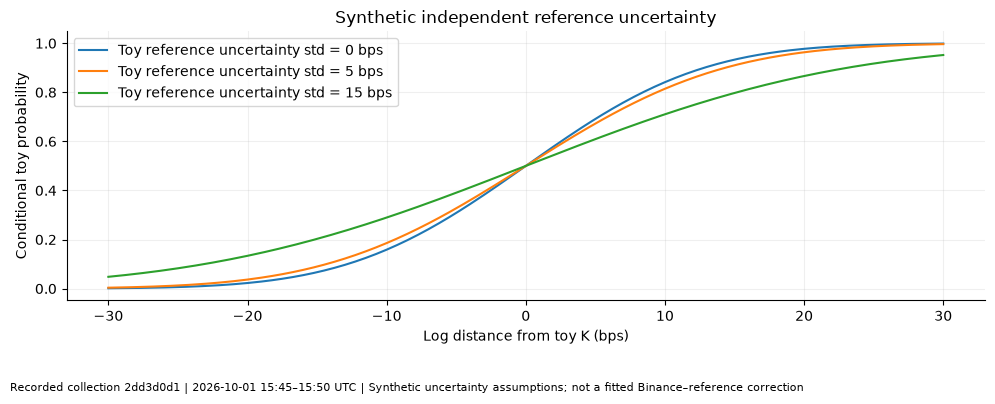

In [6]:
fig, ax = plt.subplots()
for reference_std_bps in [0, 5, 15]:
    variance_total = (10 / 10000) ** 2 + (reference_std_bps / 10000) ** 2
    ax.plot(
        distance_bps,
        digital_probability(distance_bps / 10000, variance_total),
        label=f"Toy reference uncertainty std = {reference_std_bps} bps",
    )
ax.set(
    title="Synthetic independent reference uncertainty",
    xlabel="Log distance from toy K (bps)",
    ylabel="Conditional toy probability",
)
ax.legend()
finish_plot(
    fig, sample, "Synthetic uncertainty assumptions; not a fitted Binance–reference correction"
)

## Exercise — diagnose a confident-looking model

If the proxy gives 90% and Up's midpoint is 75¢, list checks that come before
declaring a 15-cent edge. Why is terminal Brier scoring disabled here?

**Suggested answer:** verify the actual rule and threshold, source/aggregation,
time alignment, volatility forecast, jumps, payout mapping, quote depth and costs.
Without a qualified terminal label, a calibration score would measure an invented
target. A simpler model with honest uncertainty is more useful than false precision.

**Research use:** this derives a candidate probability model whose assumptions
must be qualified and tested. **Next:** [10 — Trading economics](10_trading_economics.ipynb).